# Experiment 9: Perceptron vs Multilayer Perceptron (A/B Experiment) with Hyperparameter Tuning

**Objective:** implement a Single-Layer Perceptron (PLA) from scratch and a tuned Multilayer
Perceptron (MLP), and compare them on the English Handwritten Characters dataset (62 classes:
digits 0-9, uppercase A-Z, lowercase a-z).

**Model A — PLA:** the perceptron is a binary classifier by definition (a single weight vector
with a step activation), so this notebook trains it as **One-vs-Rest**: 62 independent binary
perceptrons, one per character class, and predicts whichever one scores highest on a new image.

**Model B — MLP:** `sklearn.neural_network.MLPClassifier`, tuned over activation function,
optimizer, learning rate, and batch size via grid search.

## 1. Imports & Setup

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import label_binarize
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc
)

warnings.filterwarnings('ignore')
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelweight'] = 'bold'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Setup done.")

Setup done.


## 2. Download & Load Dataset

**This dataset is not bundled with scikit-learn — download it first.**

1. Download the "English Handwritten Characters Dataset" from Kaggle:
   https://www.kaggle.com/datasets/sujaykapadnis/english-handwritten-characters-dataset
2. Unzip it. You should get a folder containing `english.csv` (columns: `image`, `label`) and an
   `Img/` folder with the 3,410 character images (`img001-001.png` style filenames).
3. Upload that folder to Colab (or mount Drive and point `DATA_DIR` at it) and set `DATA_DIR`
   below to its path — nothing else needs to change if the folder structure is kept as
   downloaded.

In [ ]:
import zipfile
with zipfile.ZipFile("/content/archive.zip", "r") as z:
    z.extractall("/content/")
!ls "/content/Img"

In [ ]:
# If using Google Colab with the dataset in Drive, uncomment these two lines:
# from google.colab import drive
# drive.mount('/content/drive')

DATA_DIR = "/content"   # <-- change this path if your folder is elsewhere
CSV_PATH = os.path.join(DATA_DIR, "english.csv")

if not os.path.isfile(CSV_PATH):
    raise FileNotFoundError(
        f"Couldn't find '{CSV_PATH}'. Download and unzip the English Handwritten Characters "
        "Dataset (see the instructions above), and set DATA_DIR to its path before running this cell."
    )

labels_df = pd.read_csv(CSV_PATH)
print(f"Found {len(labels_df)} labeled images across {labels_df['label'].nunique()} classes.")
labels_df.head()

Found 3410 labeled images across 62 classes.


,image,label
0,Img/img001-001.png,0
1,Img/img001-002.png,0
2,Img/img001-003.png,0
3,Img/img001-004.png,0
4,Img/img001-005.png,0


## 3. Preprocessing: Load Images, Resize, Flatten, Normalize

In [ ]:
IMG_SIZE = 32   # resize every character image to 32x32 grayscale before flattening

def load_and_preprocess(labels_df, data_dir, img_size=IMG_SIZE):
    images = []
    labels = []
    for _, row in labels_df.iterrows():
        img_path = os.path.join(data_dir, row["image"])
        img = Image.open(img_path).convert("L").resize((img_size, img_size))
        images.append(np.asarray(img, dtype=np.float32).flatten())
        labels.append(row["label"])
    X = np.array(images) / 255.0   # normalize pixel values to [0, 1]
    y = np.array(labels)
    return X, y

X, y = load_and_preprocess(labels_df, DATA_DIR)
print(f"Feature matrix: {X.shape[0]} samples x {X.shape[1]} pixels (from {IMG_SIZE}x{IMG_SIZE} images)")
print(f"Classes: {len(np.unique(y))}")

Feature matrix: 3410 samples x 1024 pixels (from 32x32 images)
Classes: 62


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

classes = sorted(np.unique(y))
n_classes = len(classes)

Training samples: 2728, Test samples: 682


## 4. Exploratory Data Analysis

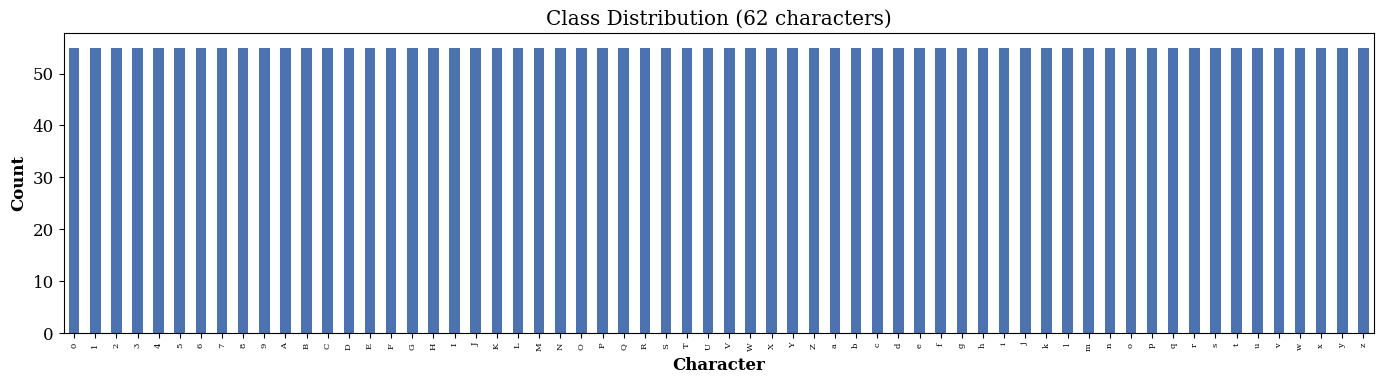

In [ ]:
plt.figure(figsize=(14, 4))
pd.Series(y).value_counts().sort_index().plot(kind='bar', color='#4c72b0')
plt.title('Class Distribution (62 characters)')
plt.xlabel('Character')
plt.ylabel('Count')
plt.xticks(fontsize=6)
plt.tight_layout()
plt.show()

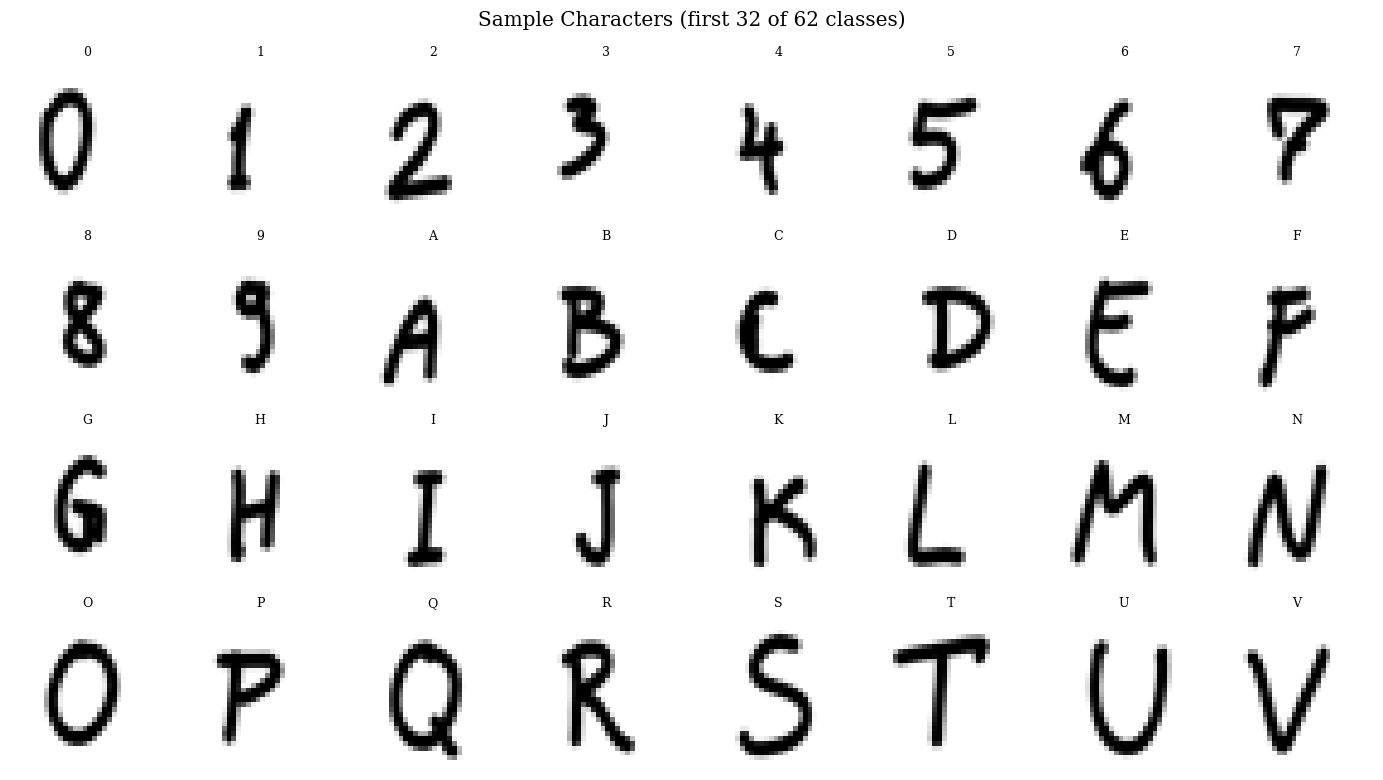

In [ ]:
# A quick grid of sample characters, one per a handful of classes
fig, axes = plt.subplots(4, 8, figsize=(14, 8))
sample_classes = classes[:32]
for ax, cls in zip(axes.flat, sample_classes):
    idx = np.where(y == cls)[0][0]
    ax.imshow(X[idx].reshape(IMG_SIZE, IMG_SIZE), cmap='gray')
    ax.set_title(cls, fontsize=9)
    ax.axis('off')
plt.suptitle('Sample Characters (first 32 of 62 classes)')
plt.tight_layout()
plt.show()

## 5. Model A — Perceptron Learning Algorithm (PLA), Implemented From Scratch
A single perceptron is a binary classifier: step activation, and the weight update rule
`w = w + eta * (y - y_hat) * x`. Since this dataset has 62 classes, One-vs-Rest wraps 62 of these
binary perceptrons — one trained to recognize "is this class C or not" — and picks whichever one
gives the highest raw score for a new image.

In [ ]:
class Perceptron:
    """Single binary perceptron: step activation + the classic perceptron update rule."""

    def __init__(self, n_features, learning_rate=0.01, n_epochs=20):
        self.lr = learning_rate
        self.n_epochs = n_epochs
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.errors_per_epoch = []

    @staticmethod
    def step(z):
        return np.where(z >= 0, 1, 0)

    def decision_function(self, X):
        return X @ self.weights + self.bias

    def fit(self, X, y):
        for epoch in range(self.n_epochs):
            errors = 0
            for xi, yi in zip(X, y):
                y_hat = self.step(np.dot(xi, self.weights) + self.bias)
                update = self.lr * (yi - y_hat)
                if update != 0.0:
                    self.weights += update * xi
                    self.bias += update
                    errors += 1
            self.errors_per_epoch.append(errors)
        return self

    def predict(self, X):
        return self.step(self.decision_function(X))

In [ ]:
class OneVsRestPerceptron:
    """Wraps one binary Perceptron per class for multi-class classification."""

    def __init__(self, classes, learning_rate=0.01, n_epochs=20):
        self.classes = list(classes)
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.classifiers = {}

    def fit(self, X, y):
        n_features = X.shape[1]
        for cls in self.classes:
            y_binary = (y == cls).astype(int)
            clf = Perceptron(n_features, self.learning_rate, self.n_epochs)
            clf.fit(X, y_binary)
            self.classifiers[cls] = clf
        return self

    def decision_scores(self, X):
        # one column of raw scores per class — used both for prediction and for ROC curves
        return np.column_stack([self.classifiers[c].decision_function(X) for c in self.classes])

    def predict(self, X):
        scores = self.decision_scores(X)
        return np.array(self.classes)[np.argmax(scores, axis=1)]

    def mean_training_errors(self):
        # average misclassification count per epoch, across all 62 binary classifiers —
        # used as the PLA convergence curve
        all_errors = np.array([clf.errors_per_epoch for clf in self.classifiers.values()])
        return all_errors.mean(axis=0)

In [ ]:
# Training 62 perceptrons sequentially over the training set can take a while — reduce
# PLA_EPOCHS if this is too slow to iterate on.
PLA_EPOCHS = 20
PLA_LR = 0.01

pla = OneVsRestPerceptron(classes=classes, learning_rate=PLA_LR, n_epochs=PLA_EPOCHS)
pla.fit(X_train, y_train)
print("PLA training complete.")

PLA training complete.


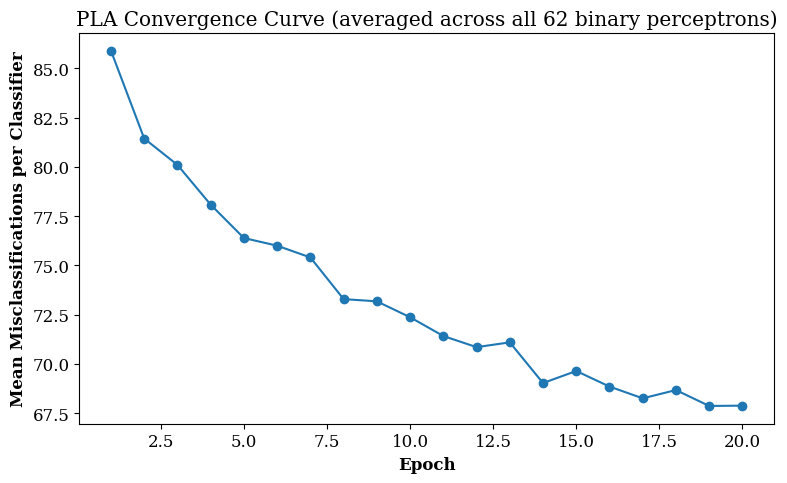

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, PLA_EPOCHS + 1), pla.mean_training_errors(), marker='o')
plt.xlabel('Epoch')
plt.ylabel('Mean Misclassifications per Classifier')
plt.title('PLA Convergence Curve (averaged across all 62 binary perceptrons)')
plt.tight_layout()
plt.show()

## 6. Evaluate PLA

In [ ]:
y_pred_pla = pla.predict(X_test)

pla_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_pla),
    "Precision (macro)": precision_score(y_test, y_pred_pla, average='macro', zero_division=0),
    "Recall (macro)": recall_score(y_test, y_pred_pla, average='macro', zero_division=0),
    "F1 Score (macro)": f1_score(y_test, y_pred_pla, average='macro', zero_division=0),
}
for k, v in pla_metrics.items():
    print(f"{k}: {v:.4f}")

Accuracy: 0.1026
Precision (macro): 0.1841
Recall (macro): 0.1026
F1 Score (macro): 0.0836


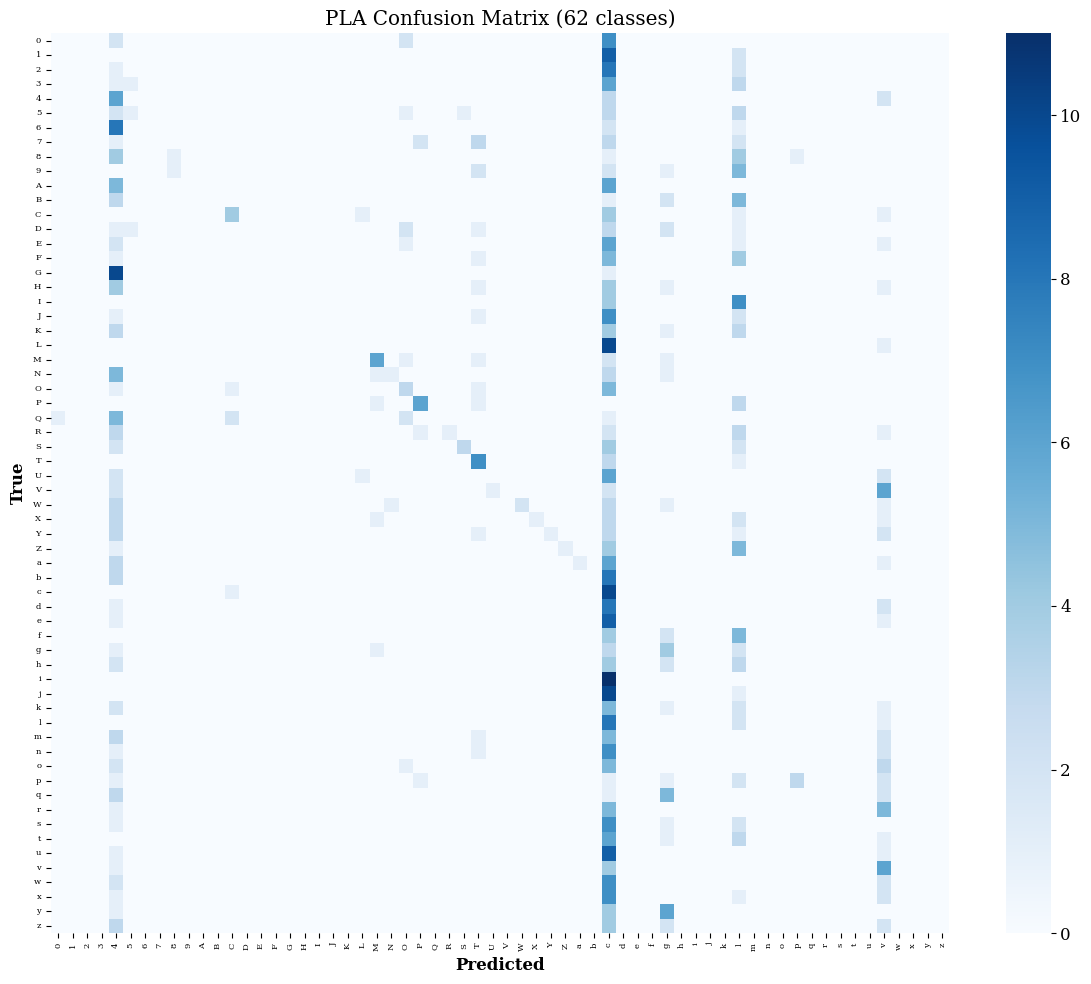

In [ ]:
cm_pla = confusion_matrix(y_test, y_pred_pla, labels=classes)
plt.figure(figsize=(12, 10))
sns.heatmap(cm_pla, cmap='Blues', xticklabels=classes, yticklabels=classes, cbar=True)
plt.title('PLA Confusion Matrix (62 classes)')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6)
plt.tight_layout()
plt.show()

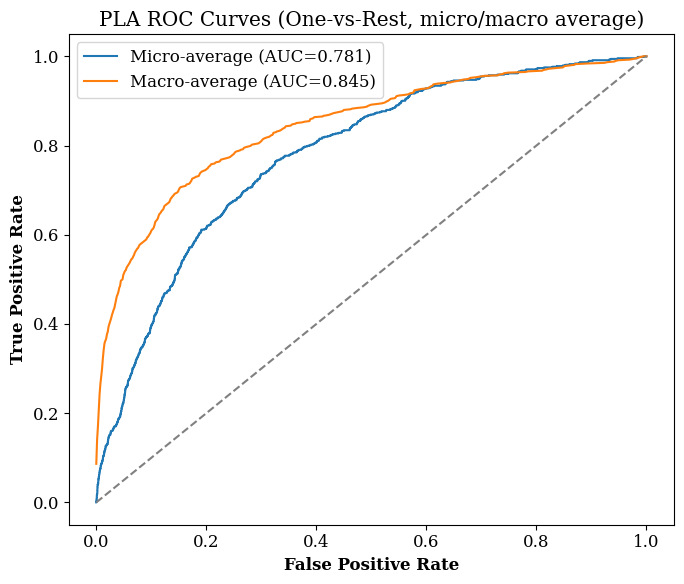

In [ ]:
# Micro/macro ROC curves need per-class scores — for PLA that's the raw decision_function
y_test_bin = label_binarize(y_test, classes=classes)
pla_scores = pla.decision_scores(X_test)

fpr_pla, tpr_pla, roc_auc_pla = {}, {}, {}
for i in range(n_classes):
    fpr_pla[i], tpr_pla[i], _ = roc_curve(y_test_bin[:, i], pla_scores[:, i])
    roc_auc_pla[i] = auc(fpr_pla[i], tpr_pla[i])

# Micro-average: flatten all classes' scores together
fpr_pla["micro"], tpr_pla["micro"], _ = roc_curve(y_test_bin.ravel(), pla_scores.ravel())
roc_auc_pla["micro"] = auc(fpr_pla["micro"], tpr_pla["micro"])

# Macro-average: average the per-class curves on a common FPR grid
all_fpr = np.unique(np.concatenate([fpr_pla[i] for i in range(n_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr_pla[i], tpr_pla[i])
mean_tpr /= n_classes
fpr_pla["macro"], tpr_pla["macro"] = all_fpr, mean_tpr
roc_auc_pla["macro"] = auc(fpr_pla["macro"], tpr_pla["macro"])

plt.figure(figsize=(7, 6))
plt.plot(fpr_pla["micro"], tpr_pla["micro"], label=f'Micro-average (AUC={roc_auc_pla["micro"]:.3f})')
plt.plot(fpr_pla["macro"], tpr_pla["macro"], label=f'Macro-average (AUC={roc_auc_pla["macro"]:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('PLA ROC Curves (One-vs-Rest, micro/macro average)')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Model B — Multilayer Perceptron (MLP)
Using `sklearn.neural_network.MLPClassifier`, which handles backpropagation internally and
exposes exactly the hyperparameters the assignment asks for: activation function, optimizer
(`solver`), learning rate, and batch size.

*Note: `MLPClassifier` with `early_stopping=True` has a known issue in some scikit-learn versions
when class labels are strings (it can throw a `TypeError` from an internal `np.isnan` check).
Labels are integer-encoded here purely to sidestep that — predictions are decoded straight back
to the original character labels afterwards, so nothing downstream needs to change.*

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Encode to integers (fit on the same sorted `classes` list used everywhere else, so the
# encoding order matches the column order already used for ROC/label_binarize below)
label_encoder = LabelEncoder().fit(classes)
y_train_enc = label_encoder.transform(y_train)

mlp_param_grid = {
    "hidden_layer_sizes": [(64,), (128,), (128, 64)],
    "activation": ["relu", "tanh"],
    "solver": ["adam", "sgd"],
    "learning_rate_init": [0.001, 0.01],
    "batch_size": [32, 64],
}

base_mlp = MLPClassifier(max_iter=300, random_state=RANDOM_STATE, early_stopping=True)

mlp_grid = GridSearchCV(
    base_mlp, mlp_param_grid, cv=3, scoring="accuracy", n_jobs=-1, verbose=1
)
mlp_grid.fit(X_train, y_train_enc)

print("Best MLP hyperparameters:", mlp_grid.best_params_)
print(f"Best CV accuracy: {mlp_grid.best_score_:.4f}")

Fitting 3 folds for each of 48 candidates, totalling 144 fits
Best MLP hyperparameters: {'activation': 'tanh', 'batch_size': 64, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.01, 'solver': 'sgd'}
Best CV accuracy: 0.3644


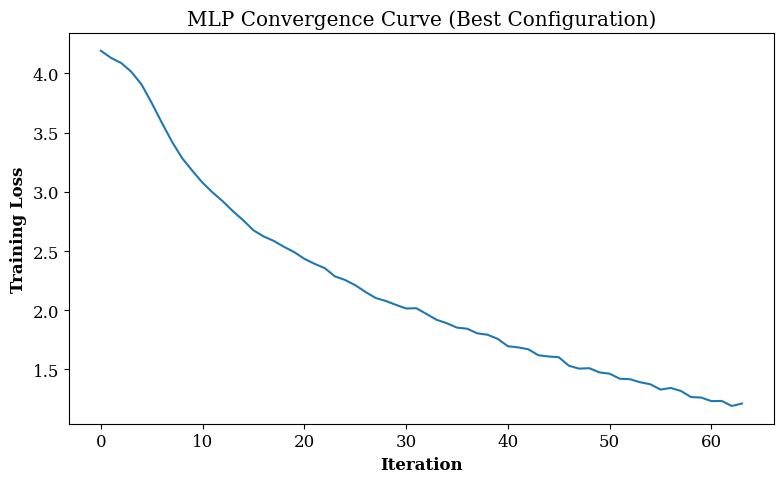

In [ ]:
best_mlp = mlp_grid.best_estimator_

plt.figure(figsize=(8, 5))
plt.plot(best_mlp.loss_curve_)
plt.xlabel('Iteration')
plt.ylabel('Training Loss')
plt.title('MLP Convergence Curve (Best Configuration)')
plt.tight_layout()
plt.show()

## 8. Evaluate MLP

In [ ]:
y_pred_mlp = label_encoder.inverse_transform(best_mlp.predict(X_test))

mlp_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_mlp),
    "Precision (macro)": precision_score(y_test, y_pred_mlp, average='macro', zero_division=0),
    "Recall (macro)": recall_score(y_test, y_pred_mlp, average='macro', zero_division=0),
    "F1 Score (macro)": f1_score(y_test, y_pred_mlp, average='macro', zero_division=0),
}
for k, v in mlp_metrics.items():
    print(f"{k}: {v:.4f}")

Accuracy: 0.4340
Precision (macro): 0.4870
Recall (macro): 0.4340
F1 Score (macro): 0.4286


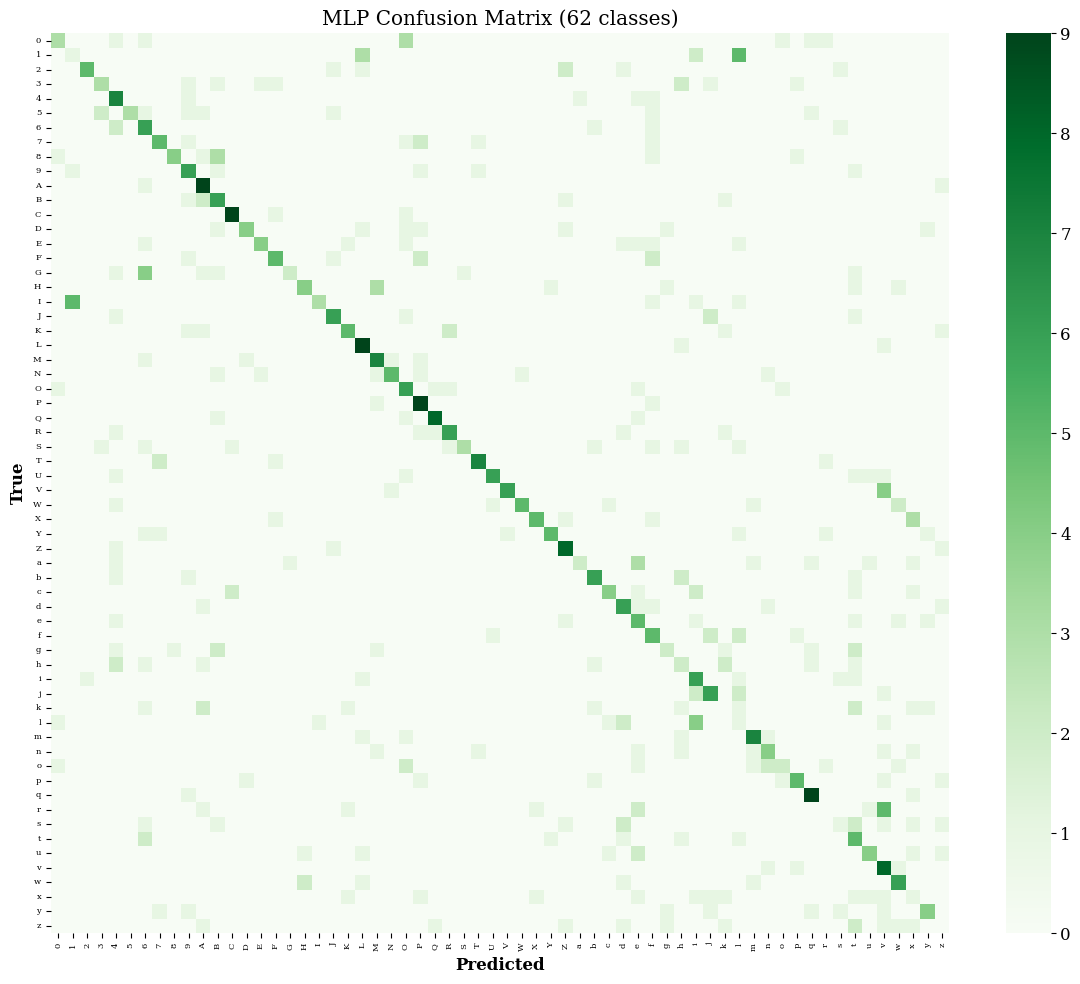

In [ ]:
cm_mlp = confusion_matrix(y_test, y_pred_mlp, labels=classes)
plt.figure(figsize=(12, 10))
sns.heatmap(cm_mlp, cmap='Greens', xticklabels=classes, yticklabels=classes, cbar=True)
plt.title('MLP Confusion Matrix (62 classes)')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6)
plt.tight_layout()
plt.show()

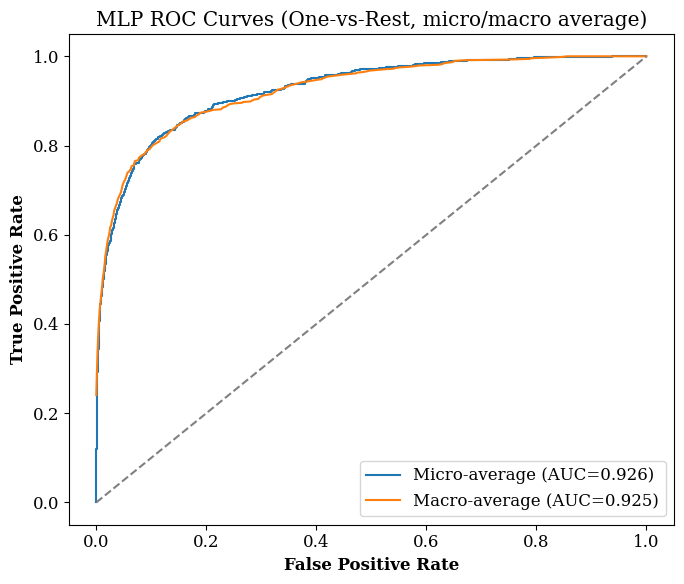

In [ ]:
mlp_scores = best_mlp.predict_proba(X_test)

fpr_mlp, tpr_mlp, roc_auc_mlp = {}, {}, {}
for i in range(n_classes):
    fpr_mlp[i], tpr_mlp[i], _ = roc_curve(y_test_bin[:, i], mlp_scores[:, i])
    roc_auc_mlp[i] = auc(fpr_mlp[i], tpr_mlp[i])

fpr_mlp["micro"], tpr_mlp["micro"], _ = roc_curve(y_test_bin.ravel(), mlp_scores.ravel())
roc_auc_mlp["micro"] = auc(fpr_mlp["micro"], tpr_mlp["micro"])

all_fpr_mlp = np.unique(np.concatenate([fpr_mlp[i] for i in range(n_classes)]))
mean_tpr_mlp = np.zeros_like(all_fpr_mlp)
for i in range(n_classes):
    mean_tpr_mlp += np.interp(all_fpr_mlp, fpr_mlp[i], tpr_mlp[i])
mean_tpr_mlp /= n_classes
fpr_mlp["macro"], tpr_mlp["macro"] = all_fpr_mlp, mean_tpr_mlp
roc_auc_mlp["macro"] = auc(fpr_mlp["macro"], tpr_mlp["macro"])

plt.figure(figsize=(7, 6))
plt.plot(fpr_mlp["micro"], tpr_mlp["micro"], label=f'Micro-average (AUC={roc_auc_mlp["micro"]:.3f})')
plt.plot(fpr_mlp["macro"], tpr_mlp["macro"], label=f'Macro-average (AUC={roc_auc_mlp["macro"]:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('MLP ROC Curves (One-vs-Rest, micro/macro average)')
plt.legend()
plt.tight_layout()
plt.show()

## 9. A/B Comparison — PLA vs MLP

In [ ]:
comparison_df = pd.DataFrame({
    "PLA": {**pla_metrics, "ROC-AUC (micro)": roc_auc_pla["micro"], "ROC-AUC (macro)": roc_auc_pla["macro"]},
    "MLP": {**mlp_metrics, "ROC-AUC (micro)": roc_auc_mlp["micro"], "ROC-AUC (macro)": roc_auc_mlp["macro"]},
}).T
display(comparison_df.round(4))

,Accuracy,Precision (macro),Recall (macro),F1 Score (macro),ROC-AUC (micro),ROC-AUC (macro)
PLA,0.1026,0.1841,0.1026,0.0836,0.7810,0.8446
MLP,0.4340,0.4870,0.4340,0.4286,0.9256,0.9249


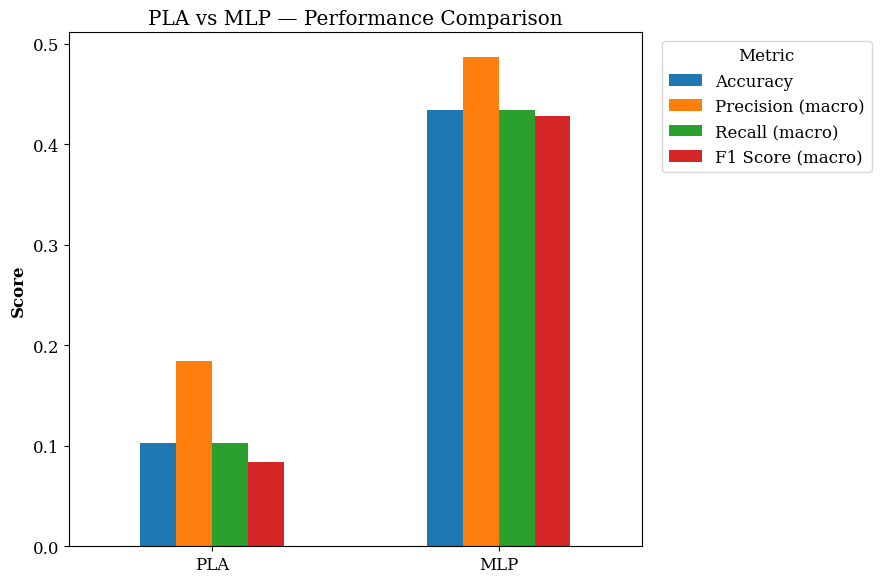

In [ ]:
comparison_df[["Accuracy", "Precision (macro)", "Recall (macro)", "F1 Score (macro)"]].plot(
    kind="bar", figsize=(9, 6)
)
plt.title("PLA vs MLP — Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
print("Best MLP hyperparameters (chosen by 3-fold CV grid search):")
for k, v in mlp_grid.best_params_.items():
    print(f"  {k}: {v}")

Best MLP hyperparameters (chosen by 3-fold CV grid search):
  activation: tanh
  batch_size: 64
  hidden_layer_sizes: (128, 64)
  learning_rate_init: 0.01
  solver: sgd


## 10. Observations

*(Fill these in with your own numbers from `comparison_df` once you've run the notebook.)*

- **Why does PLA underperform compared to MLP?** PLA can only draw a straight-line (linear)
  decision boundary per class, one-vs-rest. Handwritten characters vary in stroke shape, slant,
  and thickness in ways that are not linearly separable in raw pixel space, so a step-activation
  perceptron hits a hard ceiling that no amount of extra training epochs will fix. MLP's hidden
  layers with nonlinear activations can carve out curved decision boundaries instead.
- **Which hyperparameters had the most impact on MLP performance?** Compare `mlp_grid.cv_results_`
  (not just the single best row) to see how much accuracy moved across `activation`, `solver`,
  `learning_rate_init`, and `batch_size` individually — the one with the widest spread across its
  values had the biggest impact here.
- **Did optimizer choice (SGD vs Adam) affect convergence?** Look at the shape of the loss curve
  in Section 7 — Adam typically converges faster and more smoothly than plain SGD, especially
  in the first several iterations; if `solver='sgd'` was *not* chosen as best, that itself is
  evidence of this.
- **Did adding more hidden layers always improve results?** Compare the `(64,)`, `(128,)`, and
  `(128, 64)` rows in the grid search results — with only ~55 training images per class, a
  deeper network doesn't automatically help and can overfit faster than it learns, since there
  is comparatively little data per class.
- **Did MLP show overfitting? How could it be mitigated?** Compare training accuracy
  (`best_mlp.score(X_train, y_train)`) against the test accuracy above — a large gap indicates
  overfitting. `early_stopping=True` is already enabled in this notebook to reduce that risk;
  other options include L2 regularization (`alpha`), fewer hidden units, or more training data.

## Conclusion
A One-vs-Rest Perceptron and a hyperparameter-tuned MLP were trained on the English Handwritten
Characters dataset (62 classes) and compared on accuracy, macro precision/recall/F1, and
micro/macro ROC-AUC. The comparison table and convergence curves above are the basis for judging
how much of MLP's advantage (if any) comes from its nonlinear hidden layers versus its optimizer
and tuning, and whether that advantage comes at the cost of overfitting on this relatively small,
high-class-count dataset.